# Mix It Up - experiments notebook

This notebook re-creates the core idea of the YouTube Music recommender and
extends it with **Mix It Up**: seven songs you have never heard, based on your
taste but outside your bubble.

| Step | Machine learning used | Why |
|---|---|---|
| Song vectors | StandardScaler, one-hot, **TF-IDF + Truncated SVD (LSA)** | turn audio, genre and lyrics into numbers |
| Taste regions | **K-Means clustering**, **PCA** for the map | find the "bubbles" in the catalogue |
| Baseline | **k-Nearest Neighbours** (cosine) | how YouTube Music works today: more of the same |
| Mix It Up | comfort-zone quota + **MMR re-ranking** | relevant *and* new *and* varied |
| Feedback | **Rocchio relevance feedback**, **Logistic Regression** | learn from Save / Not for me |

Run the cells from top to bottom. All figures are also saved in `docs/images/`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

from data import load_songs, build_features, AUDIO_COLS
from recommender import BaselineRecommender, MixItUp, taste_vector
from evaluate import PERSONAS, make_history, metrics

IMG = Path.cwd().parent / "docs" / "images"
IMG.mkdir(parents=True, exist_ok=True)
GREY, PINK, PURPLE, ORANGE = "#9e9e9e", "#c2307a", "#5b2bd9", "#ff7a45"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

## 1. The data

Kaggle *Music Dataset: 1950 to 2019* (Moura et al., 2020): 28,372 songs with
lyrics, genre, six audio features and 16 lyric-topic scores. Our target group
(students) mostly listens to recent music, so we keep songs from **2000 onward**.

In [2]:
df = load_songs(min_year=2000)
print(df.shape)
df[["artist", "title", "year", "genre", "topic"] + AUDIO_COLS].head()

(10412, 33)


,artist,title,year,genre,topic,danceability,loudness,acousticness,instrumentalness,valence,energy
0,3 Doors Down,Duck And Run,2000,pop,world/life,0.500704,0.773069,0.014959,0.000072,0.849547,0.919917
1,Ricky Nelson,Hello Mary Lou,2000,pop,romantic,0.570021,0.631387,0.372489,0.000001,0.925804,0.601589
2,Modest Mouse,Perfect Disguise,2000,pop,obscene,0.493122,0.653565,0.732931,0.209514,0.120981,0.359339
3,Joe,I Believe In You,2000,pop,world/life,0.457381,0.760634,0.176706,0.000000,0.198269,0.525511
4,Fuel,Empty Spaces,2000,pop,violence,0.469295,0.814630,0.000062,0.053644,0.343570,0.943942


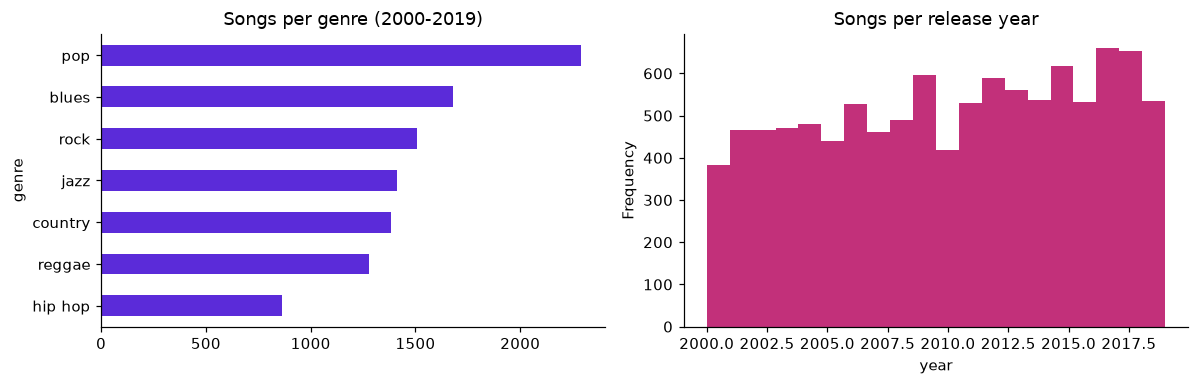

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["genre"].value_counts().plot.barh(ax=ax[0], color=PURPLE)
ax[0].invert_yaxis(); ax[0].set_title("Songs per genre (2000-2019)")
df["year"].plot.hist(bins=20, ax=ax[1], color=PINK)
ax[1].set_title("Songs per release year"); ax[1].set_xlabel("year")
plt.tight_layout(); plt.savefig(IMG / "01_dataset.png", bbox_inches="tight"); plt.show()

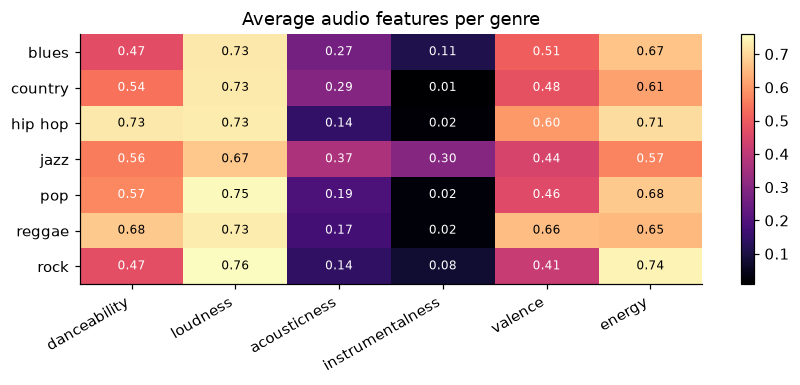

In [4]:
profile = df.groupby("genre")[AUDIO_COLS].mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(profile, cmap="magma", aspect="auto")
ax.set_xticks(range(len(AUDIO_COLS)), AUDIO_COLS, rotation=30, ha="right")
ax.set_yticks(range(len(profile)), profile.index)
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        v = profile.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < .6 else "black", fontsize=8)
ax.set_title("Average audio features per genre")
plt.colorbar(im); plt.tight_layout(); plt.savefig(IMG / "02_genre_profiles.png", bbox_inches="tight"); plt.show()

## 2. From songs to vectors

`build_features` glues four blocks together (audio, genre, lyric topics and
lyrics). The lyrics are turned into numbers with **TF-IDF** and compressed
with **Truncated SVD**. Each SVD component is a "theme"; below are the words
that define the first few themes.

In [5]:
X, info = build_features(df)
print("song matrix:", X.shape)
svd, tfidf = info["svd"], info["tfidf"]
print(f"variance kept by {svd.n_components} lyric themes: {svd.explained_variance_ratio_.sum():.1%}")
words = np.array(tfidf.get_feature_names_out())
MASK = ("fuck", "shit", "bitch", "nigg")  # hide swear words in the printout
words = np.array([w[0] + "*" * (len(w) - 1) if w.startswith(MASK) else w for w in words])
for k in range(1, 7):
    print(f"theme {k}:", ", ".join(words[np.argsort(-svd.components_[k])[:8]]))

song matrix: (10412, 53)
variance kept by 24 lyric themes: 10.5%
theme 1: away, heart, fall, time, leave, life, hold, break
theme 2: away, walk, f***, b****, like, n****, s***, break
theme 3: away, life, live, time, world, long, f***, change
theme 4: time, long, baby, night, right, tonight, good, gonna
theme 5: time, fall, f***, b****, n****, s***, n*****, mind
theme 6: feel, good, fall, time, yeah, believe, f***, need


## 3. Taste regions with K-Means

We look for natural groups in the catalogue. To choose the number of
clusters *k* we compare the **inertia** (elbow method) and the **silhouette
score** (how well songs fit their own cluster).

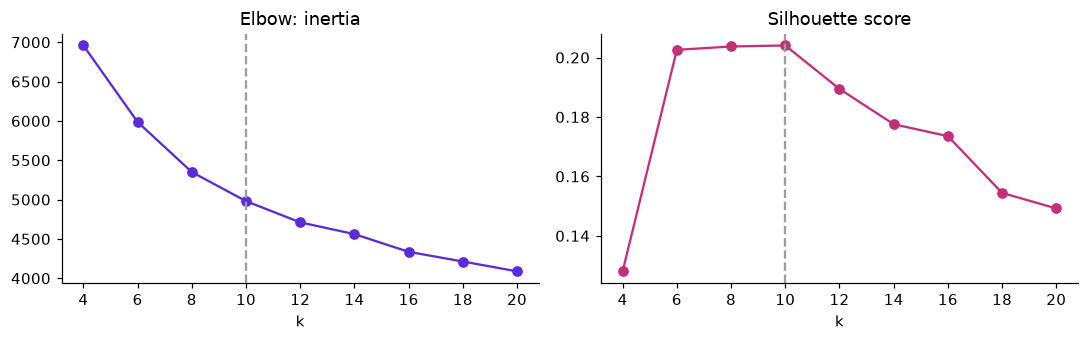

,k,inertia,silhouette
0,4,6959.0,0.128
1,6,5987.0,0.203
2,8,5350.0,0.204
3,10,4980.0,0.204
4,12,4711.0,0.189
5,14,4561.0,0.178
6,16,4336.0,0.174
7,18,4213.0,0.154
8,20,4088.0,0.149


In [6]:
ks = range(4, 21, 2)
inertia, sil = [], []
sample = np.random.default_rng(0).choice(len(X), 3000, replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X[sample], km.labels_[sample]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ks, inertia, "o-", color=PURPLE); ax[0].set_title("Elbow: inertia"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-", color=PINK); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
for a in ax: a.axvline(10, ls="--", color=GREY)
plt.tight_layout(); plt.savefig(IMG / "03_choose_k.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"k": ks, "inertia": np.round(inertia), "silhouette": np.round(sil, 3)})

In [7]:
base = BaselineRecommender(df, X)
mix = MixItUp(df, X, n_clusters=10)
pd.Series(mix.cluster_names, name="taste region").to_frame()

,taste region
0,mellow reggae · life
1,mellow pop · explicit
2,upbeat pop · explicit
3,upbeat blues · violence
4,upbeat rock · violence
5,mellow jazz · violence
6,mellow blues · sadness
7,upbeat country · explicit
8,upbeat hip hop · explicit
9,mellow country · life


## 4. Baseline vs Mix It Up for one student

Sam listens to pop and hip hop. The baseline (k-NN) recommends the songs that
are closest to Sam's average taste. Mix It Up uses the comfort-zone quota,
MMR and the filters.

In [8]:
sam = make_history(df, PERSONAS["Sam - pop & hip hop"], seed=1)
print("Sam's history:")
display(df.loc[list(sam), ["artist", "genre"]].value_counts().rename("songs").to_frame())
print("Baseline (YouTube Music today):")
display(base.recommend(sam)[["title", "artist", "genre"]])
print("Mix It Up:")
picks = mix.recommend(sam, seed=1)
display(picks[["title", "artist", "genre", "region", "reason"]])
print(mix.explain(int(picks.idx.iloc[0]), sam)["long"])

Sam's history:


,,songs
artist,genre,
Rise Against,pop,5
Florida Georgia Line,country,4
Will.I.Am,pop,4
Lil' Flip,hip hop,4
Dispatch,reggae,4
The Head And The Heart,pop,4
Nav,pop,3
Mike Will Made-It,pop,2
Florida Georgia Line,pop,1


Baseline (YouTube Music today):


,title,artist,genre
8,100% (Feat. Tony Sunshine) (Feat. Tony Sunshine),Big Pun,pop
689,Hands Up,Lloyd Banks,pop
505,All About The Benjamins,Diddy,pop
892,Six 12'S (Feat. Mouse On Tha Track),Webbie,pop
2146,Mic Drop (Steve Aoki Remix) [Full Length Edition],Bts,pop
459,Why,Jadakiss,pop
153,Bad Boy For Life,Diddy,pop


Mix It Up:


,title,artist,genre,region,reason
6338,14 Til,Anti-Lilly & Phoniks,jazz,mellow jazz · violence,Because you play Will.I.Am
8108,We Don'T Die,Twiztid,rock,upbeat rock · violence,Because you play The Head And The Heart
1485,They Roll (Feat. The Game),Nipsey Hussle,pop,upbeat pop · explicit,Because you play Nav
7391,Smoke,Inner Circle,reggae,mellow reggae · life,Because you play Lil' Flip
1393,Grown Up,Danny Brown,pop,upbeat pop · explicit,Because you play Will.I.Am
1013,Make Her Say,Kid Cudi,pop,upbeat pop · explicit,Because you play Nav
3202,A.M.,Chris Young,country,upbeat country · explicit,Because you play Florida Georgia Line


Because you play Will.I.Am: similar loudness and danceability, but a step from pop into jazz.


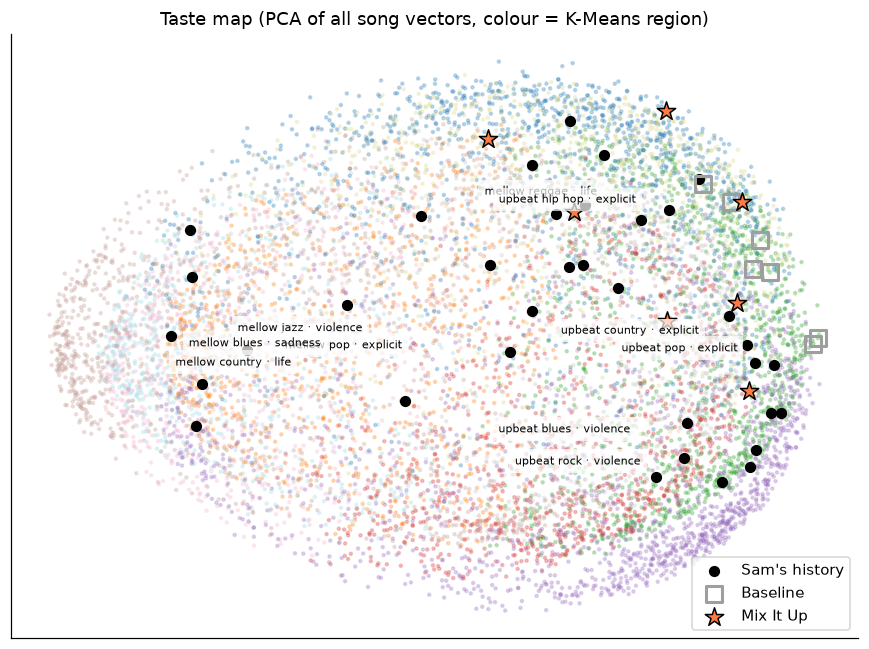

In [9]:
pca = PCA(n_components=2, random_state=0).fit(X)
P = pca.transform(X)
b_ids = list(base.recommend(sam)["idx"]); m_ids = list(picks["idx"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(P[:, 0], P[:, 1], c=mix.labels, cmap="tab20", s=4, alpha=.25)
ax.scatter(*P[list(sam)].T, s=40, c="black", label="Sam's history")
ax.scatter(*P[b_ids].T, s=110, marker="s", facecolors="none", edgecolors=GREY, lw=2, label="Baseline")
ax.scatter(*P[m_ids].T, s=160, marker="*", c=ORANGE, edgecolors="black", label="Mix It Up")
for c in range(10):
    x, y = P[mix.labels == c].mean(axis=0)
    ax.text(x, y, mix.cluster_names[c], fontsize=7, ha="center", bbox=dict(fc="white", alpha=.7, lw=0))
ax.set_title("Taste map (PCA of all song vectors, colour = K-Means region)")
ax.legend(loc="lower right"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(IMG / "04_taste_map.png", bbox_inches="tight"); plt.show()

## Experiment 1 - Does Mix It Up break the bubble?

5 student personas x 10 random histories = 50 simulated students. We measure:

* **relevance** - cosine similarity with the user's taste (higher = fits better)
* **diversity** - 1 - average similarity between the 7 songs
* **genres** - number of different genres in the 7 songs
* **new_artists** - share of artists the user never played
* **outside_bubble** - share of songs from taste regions the user does not listen to

In [10]:
rows = []
for name, mixg in PERSONAS.items():
    for s in range(10):
        h = make_history(df, mixg, seed=s)
        rows.append({"model": "Baseline", "persona": name, **metrics(base.recommend(h), h, X, df, mix)})
        rows.append({"model": "Mix It Up", "persona": name, **metrics(mix.recommend(h, seed=s), h, X, df, mix)})
exp1 = pd.DataFrame(rows)
summary = exp1.groupby("model")[["relevance", "diversity", "genres", "new_artists", "outside_bubble"]].mean().round(3)
summary

,relevance,diversity,genres,new_artists,outside_bubble
model,,,,,
Baseline,0.776,0.198,1.06,0.986,0.000
Mix It Up,0.533,0.629,4.40,1.000,0.571


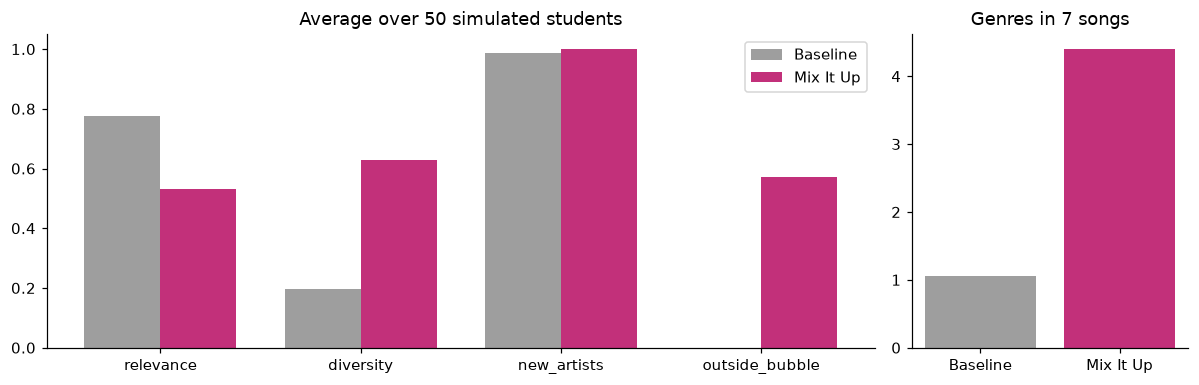

In [11]:
cols = ["relevance", "diversity", "new_artists", "outside_bubble"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 1]})
x = np.arange(len(cols)); w = .38
ax[0].bar(x - w/2, summary.loc["Baseline", cols], w, color=GREY, label="Baseline")
ax[0].bar(x + w/2, summary.loc["Mix It Up", cols], w, color=PINK, label="Mix It Up")
ax[0].set_xticks(x, cols); ax[0].set_ylim(0, 1.05); ax[0].legend(); ax[0].set_title("Average over 50 simulated students")
ax[1].bar(["Baseline", "Mix It Up"], summary["genres"], color=[GREY, PINK]); ax[1].set_title("Genres in 7 songs")
plt.tight_layout(); plt.savefig(IMG / "05_compare.png", bbox_inches="tight"); plt.show()

## Experiment 2 - How much surprise?

`surprise` (0-1) controls how many of the seven songs must come from outside
the bubble and how strongly MMR pushes for variety. More surprise costs
relevance; this is the classic accuracy-vs-diversity trade-off.

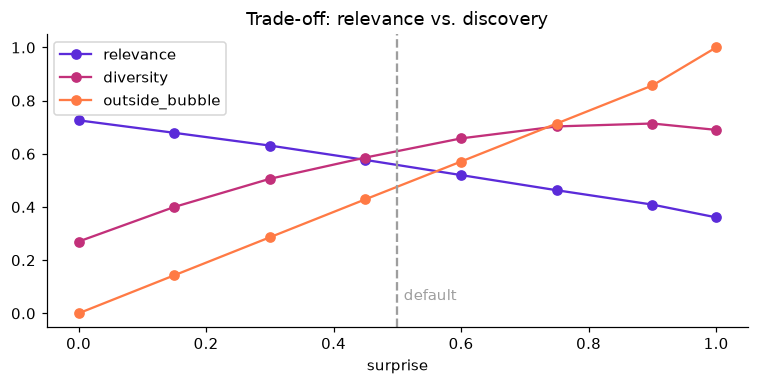

,relevance,diversity,genres,new_artists,outside_bubble
surprise,,,,,
0.00,0.726,0.270,1.067,1.0,0.000
0.15,0.679,0.400,2.033,1.0,0.143
0.30,0.631,0.506,2.800,1.0,0.286
0.45,0.577,0.586,3.667,1.0,0.429
0.60,0.520,0.658,4.500,1.0,0.571
0.75,0.463,0.703,5.333,1.0,0.714
0.90,0.409,0.714,5.567,1.0,0.857
1.00,0.361,0.690,4.600,1.0,1.000


In [12]:
rows = []
for su in [0, .15, .3, .45, .6, .75, .9, 1]:
    for name, mixg in PERSONAS.items():
        for s in range(6):
            h = make_history(df, mixg, seed=s)
            rows.append({"surprise": su, **metrics(mix.recommend(h, seed=s, surprise=su), h, X, df, mix)})
exp2 = pd.DataFrame(rows).groupby("surprise").mean().round(3)
fig, ax = plt.subplots(figsize=(7, 3.6))
for col, c in [("relevance", PURPLE), ("diversity", PINK), ("outside_bubble", ORANGE)]:
    ax.plot(exp2.index, exp2[col], "o-", color=c, label=col)
ax.axvline(.5, ls="--", color=GREY); ax.text(.51, .05, "default", color=GREY)
ax.set_xlabel("surprise"); ax.legend(); ax.set_title("Trade-off: relevance vs. discovery")
plt.tight_layout(); plt.savefig(IMG / "06_surprise.png", bbox_inches="tight"); plt.show()
exp2

## Experiment 3 - Can one song pollute your recommendations?

The UX research showed that playing one odd song (for example a kids' song
for a little brother) changes the recommendations. We add **one** song from a
genre the student never plays, give it 10 to 80 plays and measure the
**drift**: how much closer the recommendations move towards that odd song.

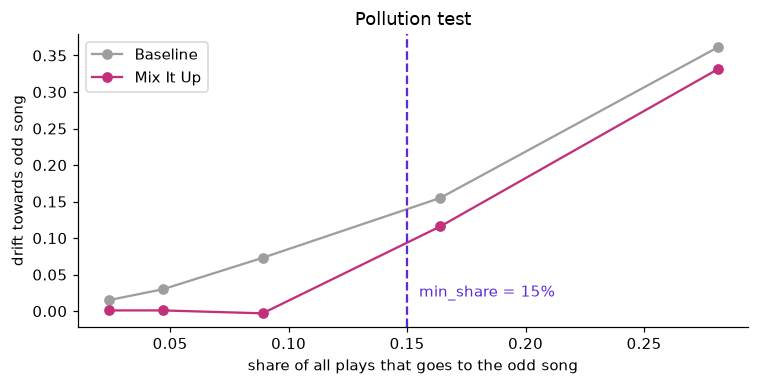

share_of_plays              drift          
model       Baseline Mix It Up Baseline Mix It Up
plays                                            
5              0.024     0.024    0.015     0.001
10             0.047     0.047    0.030     0.001
20             0.089     0.089    0.073    -0.003
40             0.164     0.164    0.155     0.116
80             0.281     0.281    0.361     0.331

In [13]:
rows = []
for plays in [5, 10, 20, 40, 80]:
    for name, mixg in PERSONAS.items():
        for s in range(10):
            h = make_history(df, mixg, seed=s)
            odd_genre = "hip hop" if "jazz" in mixg else "jazz"
            odd = int(df.index[df["genre"] == odd_genre][s * 7])
            hp = {**h, odd: plays}
            for model, rec in [("Baseline", lambda hh: base.recommend(hh)),
                               ("Mix It Up", lambda hh: mix.recommend(hh, seed=s))]:
                before, after = rec(h), rec(hp)
                rows.append({"plays": plays, "model": model,
                             "share_of_plays": plays / sum(hp.values()),
                             "drift": (X[list(after.idx)] @ X[odd]).mean() - (X[list(before.idx)] @ X[odd]).mean()})
exp3 = pd.DataFrame(rows).groupby(["plays", "model"]).mean().unstack().round(3)
fig, ax = plt.subplots(figsize=(7, 3.6))
share = exp3["share_of_plays"]["Baseline"]
ax.plot(share, exp3["drift"]["Baseline"], "o-", color=GREY, label="Baseline")
ax.plot(share, exp3["drift"]["Mix It Up"], "o-", color=PINK, label="Mix It Up")
ax.axvline(.15, ls="--", color=PURPLE); ax.text(.155, .02, "min_share = 15%", color=PURPLE)
ax.set_xlabel("share of all plays that goes to the odd song"); ax.set_ylabel("drift towards odd song")
ax.legend(); ax.set_title("Pollution test")
plt.tight_layout(); plt.savefig(IMG / "07_pollution.png", bbox_inches="tight"); plt.show()
exp3

## Experiment 4 - Leave out and the empty state

The *Leave out* filter is a hard rule: an excluded genre or artist may never
appear. When everything is filtered away, the app shows the empty state from
screen B-03e ("No new songs match your filters").

In [14]:
lotte = make_history(df, PERSONAS["Lotte - indie rock"], seed=3)
violations = 0
for s in range(50):
    r = mix.recommend(lotte, seed=s, leave_out={"genres": ["jazz", "country"], "topics": ["violence"]})
    violations += r["genre"].isin(["jazz", "country"]).sum() + (r["topic"] == "violence").sum()
print("songs that broke the Leave-out rule in 50 mixes:", violations)
everything = mix.recommend(lotte, leave_out={"genres": info["genres"]})
print("songs left when every genre is left out:", len(everything))

songs that broke the Leave-out rule in 50 mixes: 0
songs left when every genre is left out: 0


## Experiment 5 - Learning from Save / Not for me (Rocchio feedback)

We simulate a student with a hidden preference: they **save** songs that are
both energetic and positive (energy > 0.55 and valence > 0.5) and press
**Not for me** on the rest. After every round of 7 songs, Mix It Up moves the
taste profile towards the saved songs and away from the rejected ones.

base rate in catalogue: 40.0%


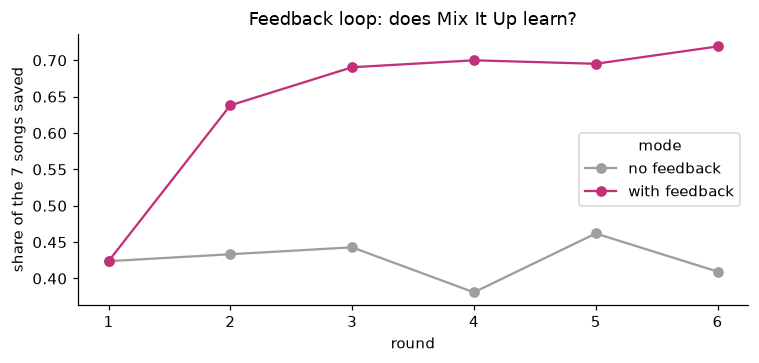

mode,no feedback,with feedback
round,,
1,0.424,0.424
2,0.433,0.638
3,0.443,0.690
4,0.381,0.700
5,0.462,0.695
6,0.410,0.719


In [15]:
def likes(i):
    return df.at[i, "energy"] > .55 and df.at[i, "valence"] > .5

print(f"base rate in catalogue: {np.mean([likes(i) for i in df.index]):.1%}")
rows = []
for name, mixg in PERSONAS.items():
    for s in range(6):
        h = make_history(df, mixg, seed=s)
        for mode in ["no feedback", "with feedback"]:
            liked, disliked = [], []
            for rnd in range(1, 7):
                r = mix.recommend(h, seed=100 * s + rnd, liked=liked, disliked=disliked)
                hits = [i for i in r.idx if likes(i)]
                rows.append({"mode": mode, "round": rnd, "saved": len(hits) / len(r)})
                if mode == "with feedback":
                    liked += hits; disliked += [i for i in r.idx if i not in hits]
exp5 = pd.DataFrame(rows).groupby(["round", "mode"])["saved"].mean().unstack()
ax = exp5.plot(marker="o", color=[GREY, PINK], figsize=(7, 3.4))
ax.set_ylabel("share of the 7 songs saved"); ax.set_title("Feedback loop: does Mix It Up learn?")
plt.tight_layout(); plt.savefig(IMG / "08_feedback.png", bbox_inches="tight"); plt.show()
exp5.round(3)

## Experiment 6 - A Logistic Regression that explains your taste

After a few weeks of Save / Not for me, we have labelled examples. A
**Logistic Regression** learns which audio features predict a save. Its
coefficients are easy to explain to a user ("you save songs with high
energy"), which supports the *Why this song?* screen.

5-fold ROC-AUC: 0.864 (+/- 0.042)


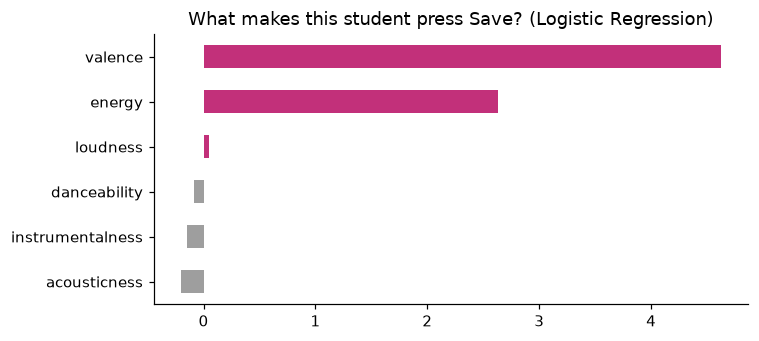

In [16]:
rng = np.random.default_rng(7)
sample = rng.choice(df.index, 400, replace=False)               # 400 songs the student rated
y = np.array([likes(i) for i in sample]) ^ (rng.random(400) < .1)  # 10% noise: people are not consistent
Xa = df.loc[sample, AUDIO_COLS].to_numpy()
clf = LogisticRegression(max_iter=1000)
auc = cross_val_score(clf, Xa, y, cv=5, scoring="roc_auc")
print(f"5-fold ROC-AUC: {auc.mean():.3f} (+/- {auc.std():.3f})")
clf.fit(Xa, y)
coef = pd.Series(clf.coef_[0], index=AUDIO_COLS).sort_values()
ax = coef.plot.barh(color=[PINK if c > 0 else GREY for c in coef], figsize=(7, 3.2))
ax.set_title("What makes this student press Save? (Logistic Regression)")
plt.tight_layout(); plt.savefig(IMG / "09_like_model.png", bbox_inches="tight"); plt.show()

## Conclusions

* The k-NN baseline is very relevant but recommends almost only one genre:
  the bubble from the UX research is reproducible with data.
* Mix It Up keeps 100% new artists, roughly triples diversity and brings
  more than half of the songs from outside the bubble, at the cost of lower
  relevance. `surprise` lets the user (or designer) pick the balance.
* The `min_share` rule makes the taste profile robust: one odd song only
  counts once it is more than ~15% of all plays.
* Leave out is a hard filter and never broken; the empty state is handled.
* Rocchio feedback and a Logistic Regression show how Save / Not for me can
  make the mix better over time and explainable.

**Limitations:** simulated users instead of real listening data, a dataset
that stops in 2019 and a few wrong genre labels in the source data.